# Experiment 1: Two-dimensional manufactured verification

Tapered cantilever of length $\ell=5$, obtained from a smooth mapping of $[-1,1]^2$, with a
variable elastic modulus $E=1+t$, $\nu_{\mathrm P}=0.3$, coupled reaction terms in the bulk
and on the boundary, and Dirichlet, traction and Robin conditions. The source and boundary
data follow from a manufactured displacement. The QTT solution with $N=2^n$, $n=2,\ldots,5$,
modes per direction is compared with a dense solution of the same discretization
(Sec. 4.1 and Fig. 4 of the paper).

In [1]:
import numpy as np
from typing import Any
from scipy.optimize import brentq
from collections import defaultdict
from matplotlib.axes import Axes
from matplotlib.ticker import ScalarFormatter, FuncFormatter, NullLocator
from matplotlib.lines import Line2D

from seemps.analysis.mesh import RegularInterval, ChebyshevInterval, Mesh
from seemps.analysis.integration.vector_quadratures import vector_fejer

from seemps_galerkin.problem import (
    TensorField,
    BoundaryProblem,
    BulkProblem,
    BoundaryFace,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
    field_to_mps,
)
from seemps_galerkin.dense.factories import (
    vec_nd_chebyshev_transform,
    op_chebyshev_vandermonde,
    op_nd_chebyshev_derivative,
)
from seemps_galerkin.mps.linear import AMEnSolver
from seemps_galerkin.logger import Logger
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform
from seemps_galerkin.mps.defaults import DEFAULT_SVD_STRATEGY
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp
from seemps_galerkin.typing import Vector, Matrix, Tensor

from tools.data import save_pkl, load_pkl, get_distance_Lp
from tools.plot import set_plot_styles, create_subplots
from tools.solver import SolverDiagnostics

set_plot_styles()

LENGTH = 5
H_BASE = 1
H_TIP = 0.2

ν_P = 0.3
δ = 2.0e-3

SVD_STRATEGY = DEFAULT_SVD_STRATEGY

## 1. Problem definition

In [2]:
def get_cantilever_modes(x: Tensor) -> tuple[list[Tensor], list[Tensor]]:
    # Third cantilever eigenvalue and normalization
    β_3 = brentq(lambda β: 1 + np.cos(β) * np.cosh(β), a=2.5 * np.pi - 0.5, b=2.5 * np.pi + 0.5)
    βx = β_3 * x
    κ_3 = (np.cosh(β_3) + np.cos(β_3)) / (np.sinh(β_3) + np.sin(β_3))

    # Modes
    Φ_stat = x**2 * (x**2 - 4 * x + 6) / 3
    Φ_3_num = np.cosh(βx) - np.cos(βx) - κ_3 * (np.sinh(βx) - np.sin(βx))
    Φ_3_den = np.cosh(β_3) - np.cos(β_3) - κ_3 * (np.sinh(β_3) - np.sin(β_3))
    Φ_3 = Φ_3_num / Φ_3_den

    # First derivative
    Φ_stat_dx = (4 * x**3 - 12 * x**2 + 12 * x) / 3
    Φ_3_dx = β_3 * (np.sinh(βx) + np.sin(βx) - κ_3 * (np.cosh(βx) - np.cos(βx))) / Φ_3_den

    # Second derivative
    Φ_stat_d2x = 4 * (x - 1) ** 2
    Φ_3_d2x = β_3**2 * (np.cosh(βx) + np.cos(βx) - κ_3 * (np.sinh(βx) + np.sin(βx))) / Φ_3_den

    # Third derivative
    Φ_stat_d3x = 8 * (x - 1)
    Φ_3_d3x = β_3**3 * (np.sinh(βx) - np.sin(βx) - κ_3 * (np.cosh(βx) + np.cos(βx))) / Φ_3_den

    return [Φ_stat, Φ_stat_dx, Φ_stat_d2x, Φ_stat_d3x], [Φ_3, Φ_3_dx, Φ_3_d2x, Φ_3_d3x]


def get_dense_problem(
    N1: int, N2: int
) -> tuple[Vector, BulkProblem[Vector], BoundaryProblem[Vector]]:
    # Build computational mesh and geometry
    itv_1 = ChebyshevInterval(-1.0, 1.0, N1, endpoints=False)
    itv_2 = ChebyshevInterval(-1.0, 1.0, N2, endpoints=False)
    mesh = Mesh([itv_1, itv_2])
    x1, x2 = mesh.to_tensor(channels_first=True)
    x, y = (1 + x1) / 2, (1 + x2) / 2

    # Build geometry and its derivatives
    h = (H_BASE - H_TIP) * x**2 * (3 - 2 * x)
    h_dx = 6 * (H_BASE - H_TIP) * x * (1 - x) / LENGTH
    h_d2x = 6 * (H_BASE - H_TIP) * (1 - 2 * x) / LENGTH**2
    Y_c = 0.5 * (H_BASE + h)
    Y_c_dx = 0.5 * h_dx
    Y_c_d2x = 0.5 * h_d2x

    # Get cantilever displacement profile
    list_Φ_stat, list_Φ_3 = get_cantilever_modes(x)
    list_Φ = [(7 / 8) * Φ_stat + (1 / 8) * Φ_3 for Φ_stat, Φ_3 in zip(list_Φ_stat, list_Φ_3)]
    w = -δ * LENGTH * list_Φ[0]
    w_dx = -δ * list_Φ[1]
    w_d2x = -(δ / LENGTH) * list_Φ[2]
    w_d3x = -(δ / LENGTH**2) * list_Φ[3]

    # Map computational grid to physical coordinates
    X = LENGTH * x
    Y = y * H_BASE + (1 - y) * h
    J = LENGTH * np.asarray(H_BASE - h) / 4

    # Get inverse transformation matrix
    Y_dx = (1 - y) * h_dx
    F_inv = np.zeros((2, 2, N1, N2))
    F_inv[0, 0] = 2 / LENGTH
    F_inv[1, 0] = -2 * Y_dx / (H_BASE - h)
    F_inv[1, 1] = 2 / (H_BASE - h)

    # Build manufactured displacement field
    u_0: Matrix = δ * X - (Y - Y_c) * w_dx
    u_1: Matrix = -δ * LENGTH + w - ν_P * δ * (Y - Y_c)
    u_exact = np.concatenate([u_0.ravel(), u_1.ravel()])

    # ==================
    # BUILD BULK PROBLEM
    # ==================

    # Get Young's modulus
    E = 1 + y
    E_dx = -(1 - y) * h_dx / (H_BASE - h)
    E_dy = 1 / (H_BASE - h)

    # Get strains
    ε_11 = δ + Y_c_dx * w_dx - (Y - Y_c) * w_d2x
    ε_22 = -ν_P * δ * np.ones_like(X)
    ε_12 = 0.5 * ν_P * δ * Y_c_dx
    ε_11_dx = Y_c_d2x * w_dx + 2 * Y_c_dx * w_d2x - (Y - Y_c) * w_d3x
    ε_11_dy = -w_d2x
    ε_12_dx = 0.5 * ν_P * δ * Y_c_d2x

    # Get derivatives of the Cauchy stress
    σ_11_dx = (E_dx * (ε_11 + ν_P * ε_22) + E * ε_11_dx) / (1 - ν_P**2)
    σ_12_dy = E_dy * ε_12 / (1 + ν_P)
    σ_12_dx = (E_dx * ε_12 + E * ε_12_dx) / (1 + ν_P)
    σ_22_dy = (E_dy * (ε_22 + ν_P * ε_11) + E * ν_P * ε_11_dy) / (1 - ν_P**2)

    # Get bulk load
    f_0 = -σ_11_dx - σ_12_dy + (1 + x) * (u_0 + 0.5 * u_1)
    f_1 = -σ_12_dx - σ_22_dy + (1 + x) * (0.5 * u_0 + u_1)

    # Get Lamé parameters
    λ_1 = E * ν_P / (1 - ν_P**2)
    λ_2 = E / (2 * (1 + ν_P))

    # Get principal-coefficient tensor field
    P = TensorField[Vector]((2, 2, 2, 2), mesh.dimensions)
    for α in range(2):
        for β in range(2):
            for μ in range(2):
                for ν in range(2):
                    entry: Matrix = np.zeros_like(X)
                    for a in range(2):
                        for b in range(2):
                            coefficient = (
                                λ_1 * (a == μ) * (b == ν)
                                + λ_2 * (a == b) * (μ == ν)
                                + λ_2 * (a == ν) * (b == μ)
                            )
                            entry += J * F_inv[α, a] * coefficient * F_inv[β, b]
                    P[α, β, μ, ν] = entry.ravel()

    # Get reaction tensor field
    R = np.array([[1.0, 0.5], [0.5, 1.0]])
    R_bulk = TensorField[Vector]((2, 2), mesh.dimensions)
    for μ in range(2):
        for ν in range(2):
            entry: Matrix = J * (1 + x) * R[μ, ν]
            R_bulk[μ, ν] = entry.ravel()

    # Get source tensor field
    f_bulk = TensorField[Vector]((2,), mesh.dimensions)
    f_bulk[0] = (J * f_0).ravel()
    f_bulk[1] = (J * f_1).ravel()

    # Get bulk problem
    bulk = BulkProblem[Vector](mesh, P, R_bulk, f_bulk)

    # ======================
    # BUILD BOUNDARY PROBLEM
    # ======================

    # Build facewise components
    x_face = (1 + itv_1.to_vector()) / 2
    h_face = (H_BASE - H_TIP) * x_face**2 * (3 - 2 * x_face)
    h_face_dx = 6 * (H_BASE - H_TIP) * x_face * (1 - x_face) / LENGTH
    Y_c_face = 0.5 * (H_BASE + h_face)
    Y_c_face_dx = 0.5 * h_face_dx
    list_Φ_stat_face, list_Φ_3_face = get_cantilever_modes(x_face)
    list_Φ_face = [
        (7 / 8) * Φ_stat + (1 / 8) * Φ_3 for Φ_stat, Φ_3 in zip(list_Φ_stat_face, list_Φ_3_face)
    ]
    dw_face = -δ * list_Φ_face[1]
    d2w_face = -(δ / LENGTH) * list_Φ_face[2]
    ε_22_face = -ν_P * δ * np.ones_like(x_face)
    ε_12_face = 0.5 * ν_P * δ * Y_c_face_dx
    R_empty = TensorField[Vector]((2, 2), (N1,))

    # Left: componentwise Dirichlet condition on u_0
    f_left = TensorField[Vector]((2,), (N2,))
    f_left[0] = np.zeros(N2)
    bc_left = DirichletBoundaryCondition(BoundaryFace(0, True), f_left)

    # Top: exact manufactured traction
    Y_top = H_BASE * np.ones(N1)
    ε_11_top = δ + Y_c_face_dx * dw_face - (Y_top - Y_c_face) * d2w_face
    E_top = 2.0
    σ_22_top = E_top * (ε_22_face + ν_P * ε_11_top) / (1 - ν_P**2)
    σ_12_top = E_top * ε_12_face / (1 + ν_P)
    f_top = TensorField[Vector]((2,), (N1,))
    f_top[0] = 0.5 * LENGTH * σ_12_top
    f_top[1] = 0.5 * LENGTH * σ_22_top
    bc_top = RobinBoundaryCondition(BoundaryFace(1, False), R_empty, f_top)

    # Bottom: exact manufactured traction
    Y_bottom = h_face
    ε_11_bottom = δ + Y_c_face_dx * dw_face - (Y_bottom - Y_c_face) * d2w_face
    E_bottom = 1.0
    σ_11_bottom = E_bottom * (ε_11_bottom + ν_P * ε_22_face) / (1 - ν_P**2)
    σ_22_bottom = E_bottom * (ε_22_face + ν_P * ε_11_bottom) / (1 - ν_P**2)
    σ_12_bottom = E_bottom * ε_12_face / (1 + ν_P)
    f_bottom = TensorField[Vector]((2,), (N1,))
    f_bottom[0] = 0.5 * LENGTH * (h_face_dx * σ_11_bottom - σ_12_bottom)
    f_bottom[1] = 0.5 * LENGTH * (h_face_dx * σ_12_bottom - σ_22_bottom)
    bc_bottom = RobinBoundaryCondition(BoundaryFace(1, True), R_empty, f_bottom)

    # Right: matrix-valued Robin condition
    y_right = (1 + itv_2.to_vector()) / 2
    x_right = np.ones(N2)
    h_right = (H_BASE - H_TIP) * x_right**2 * (3 - 2 * x_right)
    dh_right = 6 * (H_BASE - H_TIP) * x_right * (1 - x_right) / LENGTH
    Y_right = y_right * H_BASE + (1 - y_right) * h_right
    Y_c_right = 0.5 * (H_BASE + h_right)
    dY_c_right = 0.5 * dh_right
    list_Φ_stat_right, list_Φ_3_right = get_cantilever_modes(x_right)
    list_Φ_right = [
        (7 / 8) * Φ_stat + (1 / 8) * Φ_3 for Φ_stat, Φ_3 in zip(list_Φ_stat_right, list_Φ_3_right)
    ]
    w_right = -δ * LENGTH * list_Φ_right[0]
    dw_right = -δ * list_Φ_right[1]
    d2w_right = -(δ / LENGTH) * list_Φ_right[2]
    u_0_right = δ * LENGTH * x_right - (Y_right - Y_c_right) * dw_right
    u_1_right = -δ * LENGTH + w_right - ν_P * δ * (Y_right - Y_c_right)
    ε_11_right = δ + dY_c_right * dw_right - (Y_right - Y_c_right) * d2w_right
    ε_22_right = -ν_P * δ * np.ones(N2)
    ε_12_right = 0.5 * ν_P * δ * dY_c_right
    E_right = 1 + y_right
    σ_11_right = E_right * (ε_11_right + ν_P * ε_22_right) / (1 - ν_P**2)
    σ_12_right = E_right * ε_12_right / (1 + ν_P)
    surface_right = 0.5 * (H_BASE - h_right)
    robin_factor = 1 + y_right
    R_right = TensorField[Vector]((2, 2), (N2,))
    for μ in range(2):
        for ν in range(2):
            R_right[μ, ν] = surface_right * robin_factor * R[μ, ν]
    f_right = TensorField[Vector]((2,), (N2,))
    f_right[0] = surface_right * (
        σ_11_right + robin_factor * (R[0, 0] * u_0_right + R[0, 1] * u_1_right)
    )
    f_right[1] = surface_right * (
        σ_12_right + robin_factor * (R[1, 0] * u_0_right + R[1, 1] * u_1_right)
    )
    bc_right = RobinBoundaryCondition(BoundaryFace(0, False), R_right, f_right)
    boundary = BoundaryProblem(mesh, [bc_left, bc_right, bc_bottom, bc_top])
    return u_exact, bulk, boundary


def get_energy_error(u_num: Vector, N1: int, N2: int) -> float:
    mesh = Mesh([ChebyshevInterval(-1.0, 1.0, N, endpoints=False) for N in (N1, N2)])
    x1, x2 = mesh.to_tensor(channels_first=True)
    x, y = (1 + x1) / 2, (1 + x2) / 2
    h = (H_BASE - H_TIP) * x**2 * (3 - 2 * x)
    h_dx = 6 * (H_BASE - H_TIP) * x * (1 - x) / LENGTH
    Y = y * H_BASE + (1 - y) * h
    Y_c = 0.5 * (H_BASE + h)
    list_Φ_stat, list_Φ_3 = get_cantilever_modes(x)
    list_Φ = [(7 / 8) * Φ_stat + (1 / 8) * Φ_3 for Φ_stat, Φ_3 in zip(list_Φ_stat, list_Φ_3)]
    ε = np.zeros((2, 2, N1, N2))
    ε[0, 0] = δ + 0.5 * h_dx * (-δ * list_Φ[1]) - (Y - Y_c) * (-(δ / LENGTH) * list_Φ[2])
    ε[1, 1] = -ν_P * δ
    ε[0, 1] = ε[1, 0] = 0.25 * ν_P * δ * h_dx

    coefficients = vec_nd_chebyshev_transform(u_num, (2, N1, N2), which_dimensions=(1, 2)).reshape(
        2, N1 * N2
    )
    derivatives = np.empty((2, 2, N1, N2))
    for μ in range(2):
        for α in range(2):
            modal = op_nd_chebyshev_derivative((N1, N2), α) @ coefficients[μ]
            derivatives[μ, α] = vec_nd_chebyshev_transform(
                modal, (N1, N2), which_dimensions=(0, 1), inverse=True
            ).reshape(N1, N2)
    F_inv = np.zeros((2, 2, N1, N2))
    F_inv[0, 0] = 2 / LENGTH
    F_inv[1, 0] = -2 * (1 - y) * h_dx / (H_BASE - h)
    F_inv[1, 1] = 2 / (H_BASE - h)
    gradient = np.einsum("maij,anij->mnij", derivatives, F_inv, optimize=True)
    ε_num = 0.5 * (gradient + gradient.swapaxes(0, 1))

    E = 1 + y
    λ = E * ν_P / (1 - ν_P**2)
    μ = E / (2 * (1 + ν_P))
    error = ε_num - ε
    energy_error = λ * (error[0, 0] + error[1, 1]) ** 2 + 2 * μ * np.einsum(
        "abij,abij->ij", error, error
    )
    energy_exact = λ * (ε[0, 0] + ε[1, 1]) ** 2 + 2 * μ * np.einsum("abij,abij->ij", ε, ε)
    W = (
        LENGTH
        * (H_BASE - h)
        / 4
        * np.outer(vector_fejer(-1.0, 1.0, N1), vector_fejer(-1.0, 1.0, N2))
    )
    return float(np.sqrt(abs(np.sum(W * energy_error) / np.sum(W * energy_exact))))

## 2. Displacement field

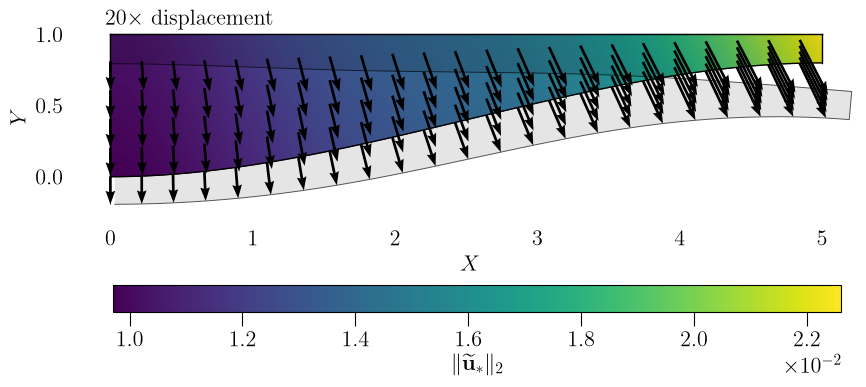

In [3]:
def plot_displacement_field(
    X: Matrix, Y: Matrix, U1: Matrix, U2: Matrix, ax: Axes, ax_colorbar: Axes
) -> None:

    # Plot displacement magnitude as the background color field
    U_abs = np.hypot(U1, U2)
    image = ax.pcolormesh(X, Y, U_abs, shading="gouraud", cmap="viridis", zorder=0, rasterized=True)

    # Sample the displacement for plotting arrows
    num_arrows_x = 25
    num_arrows_y = 5
    step_x = max(1, int(np.ceil(X.shape[1] / num_arrows_y)))
    step_y = max(1, int(np.ceil(X.shape[0] / num_arrows_x)))
    sample = np.s_[::step_y, ::step_x]
    Xs = X[sample]
    Ys = Y[sample]
    U1s = U1[sample]
    U2s = U2[sample]

    # Magnify and plot displacement vectors
    arrow_magnification = 20.0
    U1s_plot = arrow_magnification * U1s
    U2s_plot = arrow_magnification * U2s
    ax.quiver(
        Xs,
        Ys,
        U1s_plot,
        U2s_plot,
        angles="xy",
        scale_units="xy",
        scale=1,
        color="black",
        width=0.0035,
        headwidth=3.55,
        zorder=1,
    )

    # Plot the original physical boundary
    ax.plot(X[0, :], Y[0, :], color="black", linewidth=1.0, zorder=2)
    ax.plot(X[-1, :], Y[-1, :], color="black", linewidth=1.0, zorder=2)
    ax.plot(X[:, 0], Y[:, 0], color="black", linewidth=1.0, zorder=2)
    ax.plot(X[:, -1], Y[:, -1], color="black", linewidth=1.0, zorder=2)

    # Construct the displaced boundary
    X_boundary = np.concatenate([X[0, :], X[1:, -1], X[-1, -2::-1], X[-2:0:-1, 0]])
    Y_boundary = np.concatenate([Y[0, :], Y[1:, -1], Y[-1, -2::-1], Y[-2:0:-1, 0]])
    U1_boundary = np.concatenate([U1[0, :], U1[1:, -1], U1[-1, -2::-1], U1[-2:0:-1, 0]])
    U2_boundary = np.concatenate([U2[0, :], U2[1:, -1], U2[-1, -2::-1], U2[-2:0:-1, 0]])
    X_boundary_displaced = X_boundary + arrow_magnification * U1_boundary
    Y_boundary_displaced = Y_boundary + arrow_magnification * U2_boundary

    # Plot the difference between original and displaced boundaries
    ax.fill(
        np.concatenate([X_boundary, X_boundary_displaced[::-1]]),
        np.concatenate([Y_boundary, Y_boundary_displaced[::-1]]),
        facecolor="black",
        edgecolor="none",
        alpha=0.10,
        zorder=1.5,
    )
    ax.plot(
        X_boundary_displaced,
        Y_boundary_displaced,
        color="black",
        linewidth=0.7,
        alpha=0.65,
        zorder=2.5,
    )

    # Set plot limits and appearance
    x_min = min(X.min(), (Xs + U1s_plot).min())
    x_max = max(X.max(), (Xs + U1s_plot).max())
    y_min = min(Y.min(), (Ys + U2s_plot).min())
    y_max = max(Y.max(), (Ys + U2s_plot).max())
    x_padding = 0.04 * (x_max - x_min)
    y_padding = 0.04 * (y_max - y_min)
    ax.set_xlim(x_min - x_padding, x_max + x_padding)
    ax.set_ylim(y_min - y_padding, y_max + y_padding)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$X$")
    ax.set_ylabel(r"$Y$")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(False)
    ax.tick_params(bottom=False, top=False, left=False, right=False)

    # Add displacement annotation and colorbar
    ax.text(0.03, 1.1, r"$20\times$ displacement", transform=ax.transAxes, ha="left", va="top")
    colorbar = ax.figure.colorbar(image, cax=ax_colorbar, orientation="horizontal")
    colorbar.set_label(r"$\|\widetilde{\mathbf{u}}_*\|_2$", labelpad=2)
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0, 0))
    colorbar.formatter = formatter
    colorbar.update_ticks()
    ax_colorbar.xaxis.set_ticks_position("bottom")
    ax_colorbar.xaxis.set_label_position("bottom")


def _interpolate_and_plot() -> None:
    # Transform the solution to Chebyshev--Gauss nodes
    N = 32
    u_exact, _, _ = get_dense_problem(N, N)
    u_cg = vec_nd_chebyshev_transform(u_exact, (2, N, N), which_dimensions=(1, 2))
    U_cg = u_cg.reshape(2, N, N)

    # Interpolate the solution onto a finer equispaced grid
    N_plot_x, N_plot_y = 160, 80
    V_x = op_chebyshev_vandermonde(N, N_plot_x)
    V_y = op_chebyshev_vandermonde(N, N_plot_y)
    U1, U2 = np.einsum("ai,cij,bj->cab", V_x, U_cg, V_y)

    # Get the normalized plotting coordinates
    x = RegularInterval(0.0, 1.0, N_plot_x, endpoint_right=True).to_vector()
    y = RegularInterval(0.0, 1.0, N_plot_y, endpoint_right=True).to_vector()
    x_grid, y_grid = np.meshgrid(x, y, indexing="ij")

    # Map the normalized grid to the physical geometry
    X_grid = LENGTH * x_grid
    fn_h = lambda x: (H_BASE - H_TIP) * x**2 * (3 - 2 * x)
    Y_grid = y_grid * H_BASE + (1 - y_grid) * fn_h(x_grid)

    # Create and save the displacement figure
    fig, axs = create_subplots(width_px=1000, height_px=600)
    ax = axs[0, 0]
    ax_colorbar = ax.inset_axes((0.04, -0.55, 0.94, 0.15))
    plot_displacement_field(X_grid, Y_grid, U1, U2, ax, ax_colorbar)
    fig.savefig("figures/1_displacement_field.pdf", bbox_inches="tight", dpi=300)
    fig.savefig("figures/1_displacement_field.png", bbox_inches="tight", dpi=600)


_interpolate_and_plot()

## 3. Dense and QTT solutions

Results are stored in `data/1_results_dense.pkl` and `data/1_results_mps.pkl`. They are
recomputed if the files are deleted.

In [4]:
def run_dense(N1: int, N2: int) -> dict[str, Any]:
    u_exact, bulk, boundary = get_dense_problem(N1, N2)
    u_cheb = solve_dense_bvp(bulk, boundary)
    u_num = vec_nd_chebyshev_transform(
        np.real_if_close(u_cheb), (2, N1, N2), which_dimensions=(1, 2), inverse=True
    )
    error_L2 = get_distance_Lp(u_exact, u_num, p=2.0, relative=True)
    error_energy = get_energy_error(u_num, N1, N2)
    return {"error_L2": error_L2, "error_energy": error_energy}


try:
    results_dense = load_pkl("data/1_results_dense.pkl")
except FileNotFoundError:
    N_values = list(range(4, 32 + 1, 2))
    results_dense = defaultdict(list)
    for N in N_values:
        data = run_dense(N, N)
        print(f"Dense N={N}: {data}")
        results_dense["N"].append(N)
        for key, value in data.items():
            results_dense[key].append(value)
    save_pkl(dict(results_dense), "data/1_results_dense.pkl")

In [5]:
def run_mps(n1: int, n2: int, ε: float = 1e-10, enable_diagnostics: bool = False) -> dict[str, Any]:
    strategy = SVD_STRATEGY.replace(tolerance=ε, simplification_tolerance=ε)
    solver = SolverDiagnostics(
        AMEnSolver(
            maxiter=50,
            rtol=ε,
            strategy=strategy.replace(tolerance=1e-16, max_bond_dimension=128),
        )
    )

    u_exact, bulk_dense, boundary_dense = get_dense_problem(2**n1, 2**n2)

    # Assemble MPS bulk problem
    bulk = BulkProblem(
        bulk_dense.mesh,
        field_to_mps(bulk_dense.principal, strategy=strategy),
        field_to_mps(bulk_dense.reaction, strategy=strategy),
        field_to_mps(bulk_dense.source, strategy=strategy),
    )

    # Assemble MPS boundary problem
    bcs = []
    for bc in boundary_dense.boundary_conditions:
        if isinstance(bc, DirichletBoundaryCondition):
            ψ_f = field_to_mps(bc.data, strategy=strategy)
            bcs.append(DirichletBoundaryCondition(bc.face, ψ_f))
        else:
            ψ_R = field_to_mps(bc.reaction, strategy=strategy)
            ψ_f = field_to_mps(bc.data, strategy=strategy)
            bcs.append(RobinBoundaryCondition(bc.face, ψ_R, ψ_f))
    boundary = BoundaryProblem(boundary_dense.mesh, bcs)

    # Solve the linear system
    Logger.activate(level=0, collect=True)
    ψ_u_cheb = solve_mps_bvp(
        bulk, boundary, strategy=strategy, solver=solver
    )
    Logger.deactivate()

    # Return data
    ψ_u_num = mps_chebyshev_transform(
        ψ_u_cheb, [1, n1, n2], dimensions=[1, 2], inverse=True, strategy=strategy
    )
    u_num = np.real_if_close(ψ_u_num.to_vector())
    error_L2 = get_distance_Lp(u_exact, u_num, p=2.0, relative=True)
    error_energy = get_energy_error(u_num, 2**n1, 2**n2)
    if enable_diagnostics:
        return {
            "solver_converged": solver.residual <= ε,
            "solver_rtol": ε,
            "error_L2": error_L2,
            "error_energy": error_energy,
            "maxbond_u": ψ_u_cheb.max_bond_dimension(),
            "residual": solver.residual,
            "rank_operator": max(Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1]),
            "rank_source": max(Logger.sink["solve.mps.b_dirichlet.bond_dimensions"][-1]),
        }
    else:
        return {
            "solver_converged": solver.residual <= ε,
            "solver_rtol": ε,
            "error_L2": error_L2,
            "error_energy": error_energy,
            "maxbond_u": ψ_u_cheb.max_bond_dimension(),
        }


try:
    results_mps = load_pkl("data/1_results_mps.pkl")
except FileNotFoundError:
    n_values = list(range(2, 5 + 1))
    ε_values = [1e-8, 1e-9, 1e-10, 1e-11, 1e-12]

    results_mps = defaultdict(list)
    for n in n_values:
        data = run_mps(n, n, 1e-10, enable_diagnostics=False)
        print(f"MPS n={n} ε=1e-10: {data}")
        for key, value in data.items():
            results_mps[key].append(value)

    for ε in ε_values:
        data = run_mps(5, 5, ε, enable_diagnostics=True)
        print(f"MPS n=5 ε={ε}: {data}")
        for key, value in data.items():
            results_mps[key].append(value)

    save_pkl(dict(results_mps), "data/1_results_mps.pkl")

## 4. Convergence with the number of modes

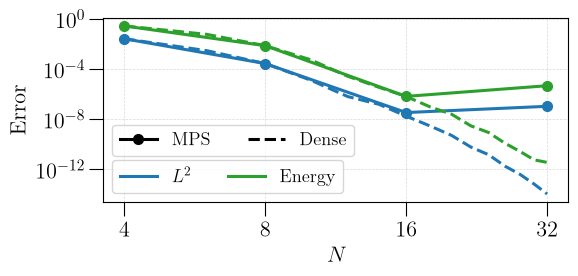

In [6]:
def plot_mps_n(ax: Axes, results_dense: dict, results_mps: dict) -> None:
    mask = slice(0, 4)
    N_mps = 2 ** np.arange(2, 6)
    for error, color in (("error_L2", "tab:blue"), ("error_energy", "tab:green")):
        ax.plot(results_dense["N"], results_dense[error], "--", color=color)
        ax.plot(N_mps, np.asarray(results_mps[error])[mask], "-o", color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xticks([4, 8, 16, 32])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel(r"$N$")
    ax.set_ylabel("Error")
    ax.grid(True, alpha=0.3)

    error_handles = [
        Line2D([0], [0], color="tab:blue", label=r"$L^2$"),
        Line2D([0], [0], color="tab:green", label="Energy"),
    ]

    method_handles = [
        Line2D([0], [0], color="black", marker="o", linestyle="-", label="MPS"),
        Line2D([0], [0], color="black", linestyle="--", label="Dense"),
    ]
    ax.add_artist(ax.legend(handles=error_handles, loc="lower left", ncol=2, fontsize="small"))
    ax.legend(
        handles=method_handles,
        loc="lower left",
        bbox_to_anchor=(0.0, 0.2),
        ncol=2,
        fontsize="small",
    )


fig, axs = create_subplots(height_px=240)
plot_mps_n(axs[0, 0], results_dense, results_mps)
fig.savefig("figures/1_error_mps_n.pdf", bbox_inches="tight")

## 5. Convergence with the truncation tolerance

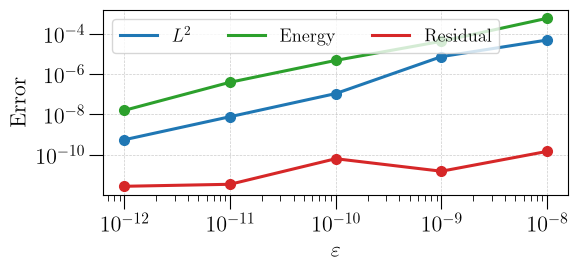

In [7]:
def plot_mps_ε(ax: Axes, results_mps: dict) -> None:
    mask = slice(-5, None)
    ε = np.asarray([1e-8, 1e-9, 1e-10, 1e-11, 1e-12])
    order = np.argsort(ε)[::-1]
    for error, color in (
        ("error_L2", "tab:blue"),
        ("error_energy", "tab:green"),
        ("residual", "tab:red"),
    ):
        ax.loglog(ε[order], np.asarray(results_mps[error])[mask][order], "-o", color=color)
    ax.set_xlabel(r"$\varepsilon$")
    ax.set_ylabel("Error")
    ax.grid(True)
    ax.legend(
        handles=[
            Line2D([0], [0], color="tab:blue", label=r"$L^2$"),
            Line2D([0], [0], color="tab:green", label="Energy"),
            Line2D([0], [0], color="tab:red", label="Residual"),
        ],
        loc="upper left",
        ncol=3,
        fontsize="small",
    )


fig, axs = create_subplots(height_px=240)
plot_mps_ε(axs[0, 0], results_mps)
fig.savefig("figures/1_error_mps_ε.pdf", bbox_inches="tight")